<a href="https://colab.research.google.com/github/asabraunfreck/IS4487-Group-Project/blob/main/Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Predicting Walmart Weekly Sales Using Machine Learning

**IS 4487 – Final Case Study Project**

## Project Overview

Walmart must accurately forecast weekly sales to manage inventory, reduce excess stock, and avoid lost sales. This project analyzes historical Walmart sales data to identify patterns related to holidays, store characteristics, weather, and economic conditions.

We will compare multiple regression models to determine which model best predicts weekly sales and provide recommendations to improve Walmart's inventory planning.
  



## 4. Data Acquisition & Loading

### 4.1 Extracting the Dataset

The Walmart Store Sales Forecasting dataset was downloaded from Kaggle. The files were provided in compressed ZIP format, so they must be extracted before they can be loaded into Python.


In [30]:

# 4.1 Download and Extract the Walmart Dataset

import os
import zipfile
import requests

# GitHub location of the Walmart dataset
zip_url = "https://raw.githubusercontent.com/asabraunfreck/IS4487-Group-Project/main/walmart-recruiting-store-sales-forecasting.zip"

# Create the data folder
folder = "/content/walmart_data"
os.makedirs(folder, exist_ok=True)

# Download the dataset from GitHub
response = requests.get(zip_url)
response.raise_for_status()

zip_path = "/content/walmart_dataset.zip"

with open(zip_path, "wb") as file:
    file.write(response.content)

# Extract the main ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(folder)

# Extract any ZIP files inside the dataset
for filename in os.listdir(folder):
    if filename.endswith(".zip"):
        file_path = os.path.join(folder, filename)

        with zipfile.ZipFile(file_path, "r") as zip_ref:
            zip_ref.extractall(folder)

# Confirm the files were extracted
print("Walmart dataset successfully downloaded!")

print("\nAvailable files:")
print(os.listdir(folder))


Walmart dataset successfully downloaded!

Available files:
['features.csv.zip', 'test.csv', 'test.csv.zip', 'features.csv', 'sampleSubmission.csv.zip', 'train.csv.zip', 'sampleSubmission.csv', 'train.csv', 'stores.csv']



### 4.2 Loading the Datasets

We will use Pandas to load the three main Walmart datasets into Python. The training dataset contains historical weekly sales, the features dataset includes weather and economic information, and the stores dataset provides store characteristics.

We will display the first five rows of each dataset to confirm that the files loaded correctly.


In [31]:

# 4.2 Load the Walmart Datasets

import pandas as pd

# Load the three datasets
train = pd.read_csv("/content/walmart_data/train.csv")
features = pd.read_csv("/content/walmart_data/features.csv")
stores = pd.read_csv("/content/walmart_data/stores.csv")

# Display the first five rows
print("Training Dataset:")
display(train.head())

print("Features Dataset:")
display(features.head())

print("Stores Dataset:")
display(stores.head())

# Confirm the datasets loaded correctly
print("\nDataset Dimensions:")
print("Training data:", train.shape)
print("Features data:", features.shape)
print("Stores data:", stores.shape)


Training Dataset:


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


Features Dataset:


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


Stores Dataset:


,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875



Dataset Dimensions:
Training data: (421570, 5)
Features data: (8190, 12)
Stores data: (45, 3)



### 4.3 Merging the Datasets

The three Walmart datasets contain different types of information. We will merge them into one dataset using their shared columns.

First, we will combine the sales data with the features data using Store, Date, and IsHoliday. Then, we will add store characteristics using the Store column.

We will use left joins to keep all historical sales records.


In [ ]:

# Merge sales with weather and economic features
walmart = pd.merge(
    train, features,
    on=["Store", "Date", "IsHoliday"],
    how="left"
)

# Add store characteristics
walmart = pd.merge(
    walmart, stores,
    on="Store",
    how="left"
)

# Check the combined dataset
print("Rows and columns:", walmart.shape)
display(walmart.head())


Rows and columns: (421570, 16)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315



### 4.4 Verifying the Merged Dataset

We will verify that the merged dataset contains the same number of rows as the original training data. We will also check whether any store information is missing after the merge.


In [ ]:

# Verify the number of records
print("Original sales rows:", len(train))
print("Merged dataset rows:", len(walmart))

# Check for missing store information
print("Missing store types:", walmart["Type"].isnull().sum())
print("Missing store sizes:", walmart["Size"].isnull().sum())

# Check the number of stores and departments
print("Number of stores:", walmart["Store"].nunique())
print("Number of departments:", walmart["Dept"].nunique())


Original sales rows: 421570
Merged dataset rows: 421570
Missing store types: 0
Missing store sizes: 0
Number of stores: 45
Number of departments: 81



### 4.5 Data Loading Summary

The three Walmart datasets were successfully loaded and merged into one dataset containing 421,570 records and 16 columns.

The merged dataset includes sales information from 45 stores and 81 departments. The number of records remained the same after merging, and no store type or size information was missing.

The combined dataset is now ready for exploratory data analysis.



## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the Walmart dataset before building predictive models. We will examine the dataset's structure, summary statistics, missing values, potential outliers, and sales patterns.

### 5.1 Initial Data Inspection

We will examine the number of rows and columns, review the data types, and inspect the first five records. This will help us identify variables that may need additional preparation.


In [ ]:

# Display dataset dimensions
print("Dataset shape:", walmart.shape)

# Display column names and data types
print("\nDataset information:")
walmart.info()

# Display the first five rows
print("\nFirst five rows:")
display(walmart.head())


Dataset shape: (421570, 16)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
 5   Temperature   421570 non-null  float64
 6   Fuel_Price    421570 non-null  float64
 7   MarkDown1     150681 non-null  float64
 8   MarkDown2     111248 non-null  float64
 9   MarkDown3     137091 non-null  float64
 10  MarkDown4     134967 non-null  float64
 11  MarkDown5     151432 non-null  float64
 12  CPI           421570 non-null  float64
 13  Unemployment  421570 non-null  float64
 14  Type          421570 non-null  object 
 15  Size          421570 non-null  int64  
dtypes: bool(1), float64(10), int64(3), object(

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315



### Initial Inspection Findings

The dataset contains 421,570 records and 16 variables. Most columns have complete data, but the five MarkDown columns contain many missing values.

The Date column is currently stored as text and will need to be converted to a datetime format for time-based analysis.

These issues will be considered during data cleaning and preprocessing.



### 5.2 Summary Statistics

We will calculate descriptive statistics for the numerical variables, including weekly sales, temperature, fuel prices, CPI, unemployment, and store size.

These statistics will help us understand typical values, variation in the data, and any unusually high or low observations.


In [ ]:

# Calculate summary statistics
summary = walmart.describe()

# Display the results
display(summary.round(2))


,Store,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size
count,421570.00,421570.00,421570.00,421570.00,421570.00,150681.00,111248.00,137091.00,134967.00,151432.00,421570.00,421570.00,421570.00
mean,22.20,44.26,15981.26,60.09,3.36,7246.42,3334.63,1439.42,3383.17,4628.98,171.20,7.96,136727.92
std,12.79,30.49,22711.18,18.45,0.46,8291.22,9475.36,9623.08,6292.38,5962.89,39.16,1.86,60980.58
min,1.00,1.00,-4988.94,-2.06,2.47,0.27,-265.76,-29.10,0.22,135.16,126.06,3.88,34875.00
25%,11.00,18.00,2079.65,46.68,2.93,2240.27,41.60,5.08,504.22,1878.44,132.02,6.89,93638.00
50%,22.00,37.00,7612.03,62.09,3.45,5347.45,192.00,24.60,1481.31,3359.45,182.32,7.87,140167.00
75%,33.00,74.00,20205.85,74.28,3.74,9210.90,1926.94,103.99,3595.04,5563.80,212.42,8.57,202505.00
max,45.00,99.00,693099.36,100.14,4.47,88646.76,104519.54,141630.61,67474.85,108519.28,227.23,14.31,219622.00



### Summary Statistics Findings

The average weekly department sales were \$15,981.26, while the median was \$7,612.03. This difference suggests that some departments generate much higher sales than others.

Weekly sales ranged from -\$4,988.94 to \$693,099.36, indicating potential outliers and negative sales values that should be investigated.

Store sizes also varied considerably, suggesting that store characteristics may help explain differences in sales performance.

These findings will help guide the data cleaning and modeling process.



### 5.3 Missing Values

Missing values can affect the accuracy of machine learning models. We will identify the number and percentage of missing values in each column.

This analysis will help determine which variables may require additional cleaning before modeling.


In [ ]:

# Count missing values in each column
missing_count = walmart.isnull().sum()

# Calculate percentage of missing values
missing_percent = (missing_count / len(walmart)) * 100

# Create a summary table
missing_data = pd.DataFrame({
    "Missing Values": missing_count,
    "Percent Missing": missing_percent
})

# Display results
display(missing_data.round(2))


,Missing Values,Percent Missing
Store,0,0.00
Dept,0,0.00
Date,0,0.00
Weekly_Sales,0,0.00
IsHoliday,0,0.00
Temperature,0,0.00
Fuel_Price,0,0.00
MarkDown1,270889,64.26
MarkDown2,310322,73.61
MarkDown3,284479,67.48



### Missing Values Findings

The missing value analysis showed that the five MarkDown columns contain substantial amounts of missing data, ranging from 64.08% to 73.61%.

MarkDown2 had the highest percentage of missing values at 73.61%.

All other variables, including Weekly_Sales, Temperature, Fuel_Price, CPI, and Unemployment, had no missing values.

The missing promotional data will need to be addressed during preprocessing before building the regression models.



### 5.4 Duplicate Records

Duplicate records can distort summary statistics and affect model accuracy. We will check for duplicate rows and repeated combinations of Store, Dept, and Date.

Each store and department should have only one sales record for each week.


In [ ]:

# Check for completely duplicated rows
duplicate_rows = walmart.duplicated().sum()

# Check for repeated store, department, and date combinations
duplicate_sales = walmart.duplicated(
    subset=["Store", "Dept", "Date"]
).sum()

# Display results
print("Completely duplicated rows:", duplicate_rows)
print("Duplicate Store-Dept-Date records:", duplicate_sales)


Completely duplicated rows: 0
Duplicate Store-Dept-Date records: 0



### Duplicate Records Findings

The dataset contains no completely duplicated rows and no duplicate combinations of Store, Dept, and Date.

This confirms that each store and department has only one sales record for each recorded week.

No duplicate records need to be removed during data cleaning.



### 5.5 Identifying Outliers

Outliers are observations that are unusually high or low compared to the rest of the dataset.

We will examine the distribution of Weekly_Sales, count negative sales values, and use the interquartile range (IQR) method to identify potential outliers.

These observations will be investigated before deciding whether they should be removed or adjusted during preprocessing.


In [ ]:

# Count negative weekly sales
negative_sales = (walmart["Weekly_Sales"] < 0).sum()

# Calculate the interquartile range
Q1 = walmart["Weekly_Sales"].quantile(0.25)
Q3 = walmart["Weekly_Sales"].quantile(0.75)
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count potential outliers
outliers = (
    (walmart["Weekly_Sales"] < lower_bound) |
    (walmart["Weekly_Sales"] > upper_bound)
).sum()

# Display results
print("Negative weekly sales:", negative_sales)
print("Lower outlier boundary:", round(lower_bound, 2))
print("Upper outlier boundary:", round(upper_bound, 2))
print("Potential outliers:", outliers)
print("Percentage of outliers:", round(outliers / len(walmart) * 100, 2), "%")


Negative weekly sales: 1285
Lower outlier boundary: -25109.65
Upper outlier boundary: 47395.16
Potential outliers: 35521
Percentage of outliers: 8.43 %



### 5.6 Weekly Sales Over Time

We will examine Walmart's total weekly sales over time to identify trends, seasonal patterns, and unusual increases or decreases in sales.

Weekly sales will be aggregated across all stores and departments to show overall sales patterns in the dataset.


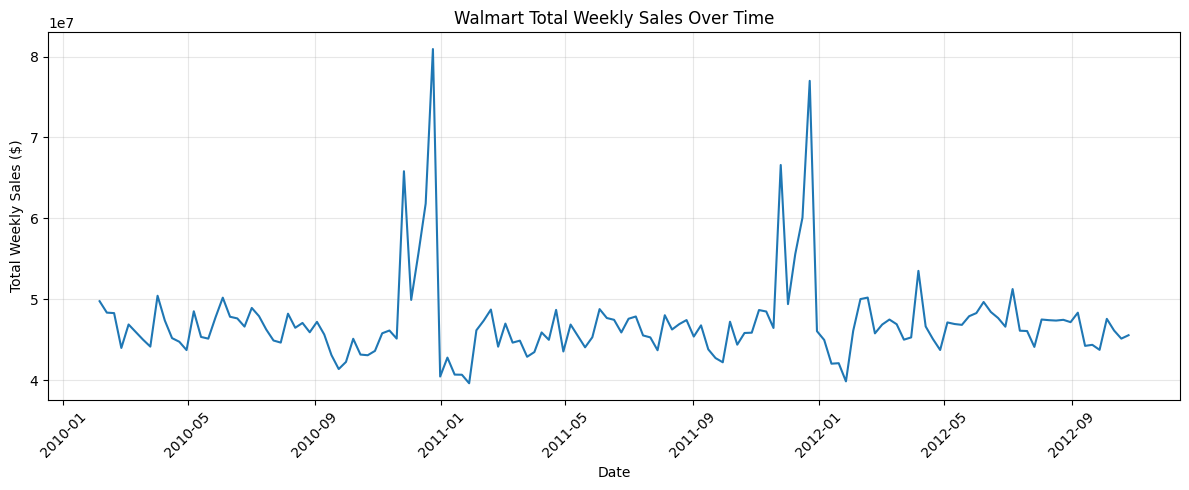

In [ ]:

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Convert Date to datetime
walmart["Date"] = pd.to_datetime(walmart["Date"])

# Calculate total sales for each week
weekly_sales = walmart.groupby("Date")["Weekly_Sales"].sum()

# Create the chart
plt.figure(figsize=(12, 5))
plt.plot(weekly_sales.index, weekly_sales.values)

plt.title("Walmart Total Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales ($)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Weekly Sales Trend Findings

Walmart's weekly sales remained relatively consistent throughout most of the year, generally ranging between \$40 million and \$50 million across the stores included in the dataset.

However, sales increased significantly near the end of both 2010 and 2011, likely due to holiday shopping demand.

Sales also declined sharply after these peaks, suggesting a recurring seasonal pattern.

These findings indicate that holidays and seasonal trends may be important factors when forecasting weekly sales and planning inventory.



### 5.7 Holiday vs. Non-Holiday Sales

We will compare average weekly department sales during holiday and non-holiday weeks.

This analysis will help determine whether holiday periods are associated with higher sales and whether holiday information may be useful for predicting future demand.


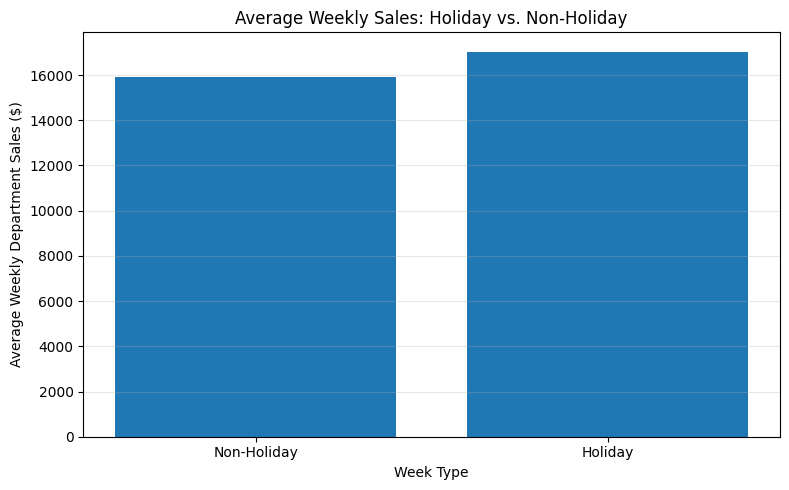

IsHoliday
False    15901.45
True     17035.82
Name: Weekly_Sales, dtype: float64


In [ ]:

# Calculate average weekly sales by holiday status
holiday_sales = walmart.groupby("IsHoliday")["Weekly_Sales"].mean()

# Create labels
labels = ["Non-Holiday", "Holiday"]

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(labels, holiday_sales.values)

plt.title("Average Weekly Sales: Holiday vs. Non-Holiday")
plt.xlabel("Week Type")
plt.ylabel("Average Weekly Department Sales ($)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Display average sales values
print(holiday_sales.round(2))



### Holiday Sales Findings

Average weekly department sales were \$17,035.82 during holiday weeks compared to \$15,901.45 during non-holiday weeks.

This represents an increase of approximately 7.13% during holiday weeks.

These findings suggest that holidays are associated with higher sales and may be an important factor when forecasting future demand.

Walmart could use these seasonal patterns to improve inventory planning and prepare for periods of increased customer demand.



### 5.8 Average Weekly Sales by Store Type

We will compare average weekly department sales across Walmart's three store types: A, B, and C.

This analysis will help determine whether store characteristics are associated with differences in sales performance.


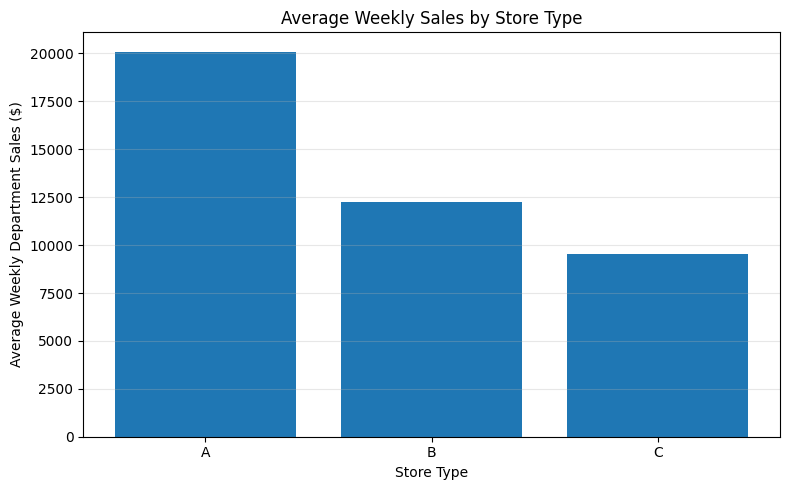

Type
A    20099.57
B    12237.08
C     9519.53
Name: Weekly_Sales, dtype: float64


In [ ]:

# Calculate average weekly sales by store type
store_type_sales = walmart.groupby("Type")["Weekly_Sales"].mean()

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(store_type_sales.index, store_type_sales.values)

plt.title("Average Weekly Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Weekly Department Sales ($)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Display average sales values
print(store_type_sales.round(2))



### Store Type Findings

Type A stores had the highest average weekly department sales at \$20,099.57, followed by Type B stores at \$12,237.08 and Type C stores at \$9,519.53.

Type A stores generated approximately 111% higher average weekly department sales than Type C stores.

These differences suggest that store characteristics may be important factors in predicting weekly sales.

Walmart could use this information to develop inventory strategies that account for differences in demand across store types.



### 5.9 Relationship Between Store Size and Weekly Sales

We will examine the relationship between store size and average weekly department sales.

A scatter plot will help us determine whether larger stores tend to generate higher sales and whether store size may be a useful variable for predicting future demand.


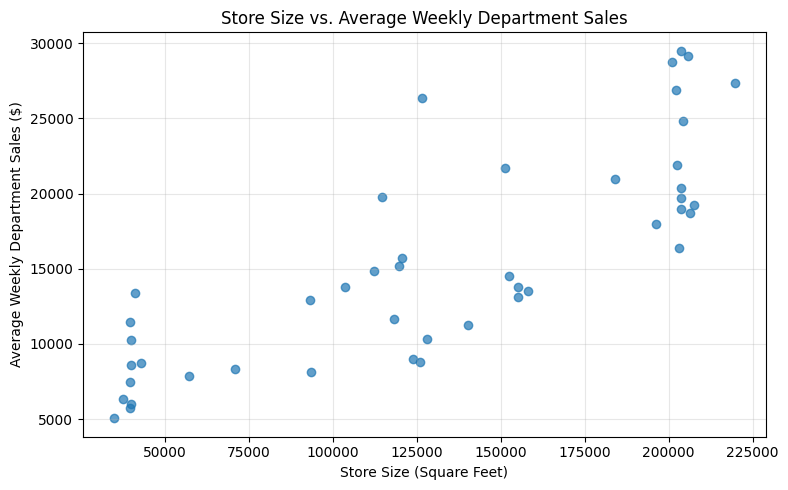

Correlation between store size and sales: 0.807


In [ ]:

# Calculate average weekly department sales for each store
store_size_sales = walmart.groupby("Store").agg({
    "Size": "first",
    "Weekly_Sales": "mean"
}).reset_index()

# Create scatter plot
plt.figure(figsize=(8, 5))
plt.scatter(
    store_size_sales["Size"],
    store_size_sales["Weekly_Sales"],
    alpha=0.7
)

plt.title("Store Size vs. Average Weekly Department Sales")
plt.xlabel("Store Size (Square Feet)")
plt.ylabel("Average Weekly Department Sales ($)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate correlation
correlation = store_size_sales["Size"].corr(
    store_size_sales["Weekly_Sales"]
)

print("Correlation between store size and sales:", round(correlation, 3))



### Store Size Findings

The scatter plot shows a strong positive relationship between store size and average weekly department sales.

The correlation coefficient was 0.807, indicating that larger Walmart stores generally have higher average weekly department sales.

However, some stores of similar sizes have different sales levels, suggesting that other factors also influence sales performance.

These findings suggest that store size may be an important variable to include in the machine learning models.

Walmart could use store size alongside other factors to improve sales forecasting and inventory planning.



### 5.10 Distribution of Weekly Sales

We will examine the distribution of weekly department sales using a histogram.

This visualization will help identify whether sales are evenly distributed or concentrated within certain ranges.

We will also investigate whether unusually high sales values affect the overall distribution.


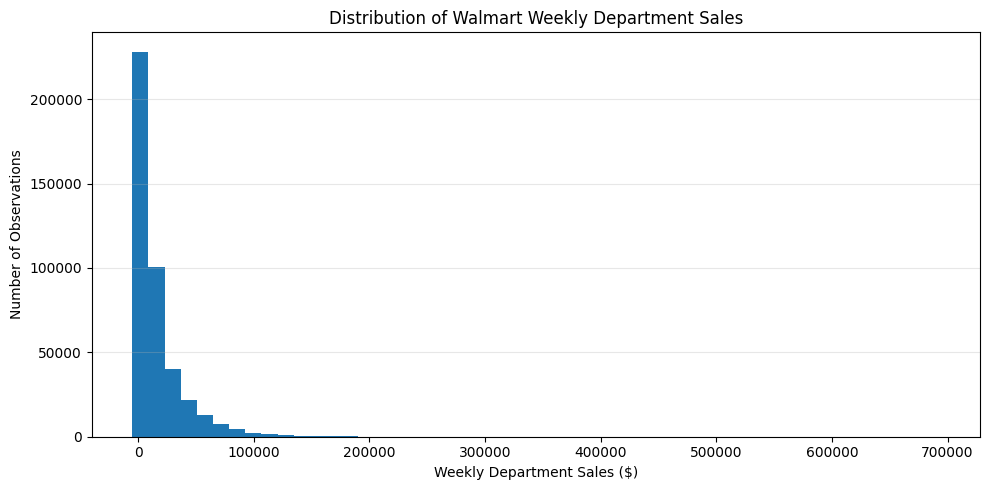

Mean weekly sales: 15981.26
Median weekly sales: 7612.03
Maximum weekly sales: 693099.36


In [ ]:

# Create histogram of weekly sales
plt.figure(figsize=(10, 5))

plt.hist(walmart["Weekly_Sales"], bins=50)

plt.title("Distribution of Walmart Weekly Department Sales")
plt.xlabel("Weekly Department Sales ($)")
plt.ylabel("Number of Observations")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Display sales statistics
print("Mean weekly sales:", round(walmart["Weekly_Sales"].mean(), 2))
print("Median weekly sales:", round(walmart["Weekly_Sales"].median(), 2))
print("Maximum weekly sales:", round(walmart["Weekly_Sales"].max(), 2))



### Weekly Sales Distribution Findings

The histogram shows that Walmart's weekly department sales are strongly right-skewed, with most observations concentrated at lower sales values.

The average weekly department sales were \$15,981.26, while the median was \$7,612.03.

The maximum weekly sales value was \$693,099.36, indicating that some departments generate exceptionally high sales.

These findings suggest that outliers and differences between departments may affect model performance.

During preprocessing, the group should investigate unusually high and negative sales values before deciding whether adjustments are necessary.



### 5.11 EDA Summary and Key Findings

Our exploratory data analysis identified several important patterns in Walmart's historical weekly sales.

1. Holiday weeks had approximately 7.13% higher average weekly department sales than non-holiday weeks.

2. Type A stores generated substantially higher average weekly department sales than Type B and Type C stores.

3. Store size had a strong positive correlation of 0.807 with average weekly department sales.

4. Weekly department sales were strongly right-skewed, with several unusually high sales observations.

5. The five MarkDown variables contained substantial missing data, ranging from 64.08% to 73.61%.

6. The dataset contained no duplicate records, but 1,285 negative sales observations and 35,521 potential outliers were identified.

These findings suggest that store characteristics, holidays, and seasonal patterns may be useful predictors of weekly sales.

Before modeling, the group should address missing promotional data, investigate unusual sales values, and prepare categorical and date variables for analysis.
